# Digital Advertising Budget Optimizer
## Notebook 02 — Exploratory Analysis & KPIs (Pandas)

**Goal:** understand how each platform, campaign and audience performs, using the full 10M-row dataset.

**Outline**
1. Setup & load data
2. Data quality checks
3. KPI definitions
4. Overall performance
5. Platform performance
6. Campaign performance
7. Audience performance (age, gender, city, device)
8. Trends over time
9. Diminishing returns (preview of Notebook 06)
10. Key insights & saved outputs

**Requires:** Notebook 01 completed. Runtime: standard CPU.

In [1]:
# ============================================================
# 1. Setup
# ============================================================
import os, sys, shutil, time, json
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_NAME = "ad-budget-optimizer"
if IN_COLAB:
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
    LOCAL_DIR = Path("/content") / PROJECT_NAME
else:
    DRIVE_DIR = LOCAL_DIR = Path.cwd() / PROJECT_NAME

SRC_DIR = DRIVE_DIR / "src"
FIG_DIR = DRIVE_DIR / "outputs/figures"
REP_DIR = DRIVE_DIR / "outputs/reports"
PROC_DIR = DRIVE_DIR / "data/processed"
for d in (FIG_DIR, REP_DIR, PROC_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))

DATASET = "10m"   # largest dataset = most accurate numbers

# Copy data from Drive to fast local disk (much quicker to read than Drive)
src_pq = DRIVE_DIR / "data/raw/parquet" / f"ads_{DATASET}"
local_pq = LOCAL_DIR / "data/raw/parquet" / f"ads_{DATASET}"
assert src_pq.exists(), f"{src_pq} not found. Run Notebook 01 first."
if not local_pq.exists():
    t0 = time.time()
    shutil.copytree(src_pq, local_pq)
    print(f"Copied ads_{DATASET} from Drive to local disk in {time.time() - t0:.0f}s")

CONFIG = json.loads((DRIVE_DIR / "config/generator_config.json").read_text())
print("Data:", local_pq)

Mounted at /content/drive
Copied ads_10m from Drive to local disk in 13s
Data: /content/ad-budget-optimizer/data/raw/parquet/ads_10m


Shared code: `kpis.py` holds the KPI formulas and `viz.py` the chart style. Notebooks 03–07 reuse both, so every tool computes KPIs exactly the same way.

In [2]:
%%writefile {SRC_DIR}/kpis.py
"""
kpis.py — Single source of truth for KPI definitions (used by every notebook).

Rule: KPIs are always a RATIO OF TOTALS (total clicks / total impressions),
never an average of row-level ratios, which over-weights tiny rows and breaks
when a row has zero clicks or conversions.
"""
import numpy as np
import pandas as pd

METRICS = ["impressions", "clicks", "spend", "conversions", "revenue"]


def _div(a, b):
    return a / b.replace(0, np.nan)


def add_kpis(agg):
    """Add KPI columns to a DataFrame of summed base metrics."""
    t = agg.copy()
    t["CTR_%"] = 100 * _div(t["clicks"], t["impressions"])
    t["CPC"] = _div(t["spend"], t["clicks"])
    t["CVR_%"] = 100 * _div(t["conversions"], t["clicks"])
    t["CPA"] = _div(t["spend"], t["conversions"])
    t["ROAS"] = _div(t["revenue"], t["spend"])
    t["spend_share_%"] = 100 * t["spend"] / t["spend"].sum()
    t["revenue_share_%"] = 100 * t["revenue"] / t["revenue"].sum()
    return t


def kpi_table(df, by, sort_by="ROAS"):
    """Group by one or more columns, sum base metrics, add KPIs."""
    t = add_kpis(df.groupby(by, observed=True)[METRICS].sum())
    return t.sort_values(sort_by, ascending=False) if sort_by else t


def overall(df):
    """Headline KPIs for the whole dataset."""
    s = df[METRICS].sum()
    return pd.Series({
        "Total spend (Rs M)": s["spend"] / 1e6,
        "Total revenue (Rs M)": s["revenue"] / 1e6,
        "Impressions (M)": s["impressions"] / 1e6,
        "Clicks (M)": s["clicks"] / 1e6,
        "Conversions (K)": s["conversions"] / 1e3,
        "CTR %": 100 * s["clicks"] / s["impressions"],
        "CPC (Rs)": s["spend"] / s["clicks"],
        "Conversion rate %": 100 * s["conversions"] / s["clicks"],
        "CPA (Rs)": s["spend"] / s["conversions"],
        "ROAS": s["revenue"] / s["spend"],
    }).round(2)


def view(t):
    """Presentation-ready version of a kpi_table (Rs in millions, rounded)."""
    return pd.DataFrame({
        "Spend (Rs M)": t["spend"] / 1e6,
        "Revenue (Rs M)": t["revenue"] / 1e6,
        "Spend share %": t["spend_share_%"],
        "Revenue share %": t["revenue_share_%"],
        "CTR %": t["CTR_%"],
        "CPC (Rs)": t["CPC"],
        "Conv. rate %": t["CVR_%"],
        "CPA (Rs)": t["CPA"],
        "ROAS": t["ROAS"],
    }, index=t.index).round(2)

Writing /content/drive/MyDrive/ad-budget-optimizer/src/kpis.py


In [3]:
%%writefile {SRC_DIR}/viz.py
"""viz.py — Shared chart style and helpers (consistent look across notebooks)."""
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

PLATFORM_COLORS = {"Facebook": "#1877F2", "Instagram": "#C13584", "Google": "#34A853",
                   "TikTok": "#222222", "YouTube": "#FF0000"}
PLATFORM_ORDER = list(PLATFORM_COLORS)
NEUTRAL = "#9AA3B2"
ACCENT = "#2F3B52"


def apply_style():
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
        "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10,
    })


def colors_for(names):
    return [PLATFORM_COLORS.get(n, NEUTRAL) for n in names]


def platform_legend(ax, **kw):
    ax.legend(handles=[Patch(color=c, label=p) for p, c in PLATFORM_COLORS.items()], **kw)


def save(fig, folder, name):
    path = Path(folder) / f"{name}.png"
    fig.savefig(path, facecolor="white")
    return path

Writing /content/drive/MyDrive/ad-budget-optimizer/src/viz.py


In [4]:
import importlib
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown

import kpis, viz
importlib.reload(kpis); importlib.reload(viz)
viz.apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

t0 = time.time()
df = pq.read_table(local_pq).to_pandas(date_as_object=False)
load_s = time.time() - t0
mem_mb = df.memory_usage(deep=True).sum() / 1e6
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns in {load_s:.1f}s  |  {mem_mb:,.0f} MB in RAM")
print(f"Date range: {df.date.min():%d %b %Y} to {df.date.max():%d %b %Y}")
df.head()

Loaded 10,000,000 rows x 12 columns in 1.8s  |  540 MB in RAM
Date range: 01 Nov 2025 to 31 Oct 2026


,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device
0,2026-08-17,IG_Promo_02,Instagram,4875,51,915.67,0,0.0,18-24,Female,Islamabad,Mobile
1,2026-07-23,GG_Prospecting_01,Google,470,11,442.70,0,0.0,18-24,Female,Faisalabad,Mobile
2,2026-10-19,IG_Prospecting_01,Instagram,14636,164,2219.07,0,0.0,18-24,Male,Peshawar,Mobile
3,2026-03-27,FB_Brand_01,Facebook,2405,21,388.82,0,0.0,25-34,Male,Islamabad,Mobile
4,2026-05-12,IG_Prospecting_01,Instagram,4176,50,690.56,0,0.0,18-24,Male,Karachi,Mobile


## 2. Data quality checks
Before analysing anything, confirm the data obeys basic business logic.
A professional pipeline runs these checks every time new data arrives.

In [5]:
start, end = pd.Timestamp(CONFIG["date_range"][0]), pd.Timestamp(CONFIG["date_range"][1])
checks = {
    "No missing values":              df.isna().any(axis=1).sum(),
    "No duplicate rows":              df.duplicated().sum(),
    "Spend > 0":                      (df.spend <= 0).sum(),
    "Impressions > 0":                (df.impressions <= 0).sum(),
    "Clicks <= impressions":          (df.clicks > df.impressions).sum(),
    "Conversions <= clicks":          (df.conversions > df.clicks).sum(),
    "Revenue >= 0":                   (df.revenue < 0).sum(),
    "No revenue without conversions": ((df.conversions == 0) & (df.revenue > 0)).sum(),
    "Dates within expected range":    (~df.date.between(start, end)).sum(),
    "Known platforms only":           (~df.platform.isin(CONFIG["platforms"].keys())).sum(),
}
quality = pd.DataFrame({"violating_rows": pd.Series(checks).astype(int)})
quality["status"] = np.where(quality.violating_rows == 0, "PASS", "FAIL")
quality.to_csv(REP_DIR / "02_data_quality.csv")
display(quality)
print(f"{(quality.status == 'PASS').sum()}/{len(quality)} checks passed")

,violating_rows,status
No missing values,0,PASS
No duplicate rows,0,PASS
Spend > 0,0,PASS
Impressions > 0,0,PASS
Clicks <= impressions,0,PASS
Conversions <= clicks,0,PASS
Revenue >= 0,0,PASS
No revenue without conversions,0,PASS
Dates within expected range,0,PASS
Known platforms only,0,PASS


10/10 checks passed


## 3. KPI definitions

| KPI | Formula | What it tells management |
|---|---|---|
| **CTR** (click-through rate) | clicks ÷ impressions | Is the ad attractive to the people who see it? |
| **CPC** (cost per click) | spend ÷ clicks | How expensive is traffic? |
| **Conversion rate** | conversions ÷ clicks | Do visitors actually buy? |
| **CPA** (cost per acquisition) | spend ÷ conversions | What does one customer cost? |
| **ROAS** (return on ad spend) | revenue ÷ spend | Rs. of revenue per Rs. 1 spent (the key metric for budget decisions) |

All KPIs are computed as **ratios of totals** (sum of clicks ÷ sum of impressions), not averages of row-level ratios.
Averaging row ratios over-weights tiny rows and breaks on rows with zero conversions.

## 4. Overall performance

In [6]:
overall = kpis.overall(df)
overall.to_frame("value").to_csv(REP_DIR / "02_kpi_overall.csv")
display(overall.to_frame("value").style.format("{:,.2f}"))

,value
Total spend (Rs M),"19,153.77"
Total revenue (Rs M),"63,335.47"
Impressions (M),"129,350.06"
Clicks (M),"1,257.97"
Conversions (K),"22,639.06"
CTR %,0.97
CPC (Rs),15.23
Conversion rate %,1.80
CPA (Rs),846.05
ROAS,3.31


> **Note on absolute totals:** totals (spend, revenue) grow with dataset size, because every extra row is extra activity.
> Budget decisions rely on **ratios** (ROAS, CPA, shares), which stay constant across all dataset sizes (validated in Notebook 01).

## 5. Platform performance

,Spend (Rs M),Revenue (Rs M),Spend share %,Revenue share %,CTR %,CPC (Rs),Conv. rate %,CPA (Rs),ROAS
platform,,,,,,,,,
Google,3832.29,17198.11,20.01,27.15,3.0,30.01,3.79,791.16,4.49
Instagram,4785.78,16894.96,24.99,26.68,1.0,18.00,1.90,946.97,3.53
Facebook,5746.80,18270.77,30.00,28.85,1.2,12.51,1.90,657.34,3.18
TikTok,2872.83,7509.36,15.00,11.86,0.8,8.75,0.95,918.90,2.61
YouTube,1916.08,3462.28,10.00,5.47,0.4,25.00,1.14,2196.01,1.81


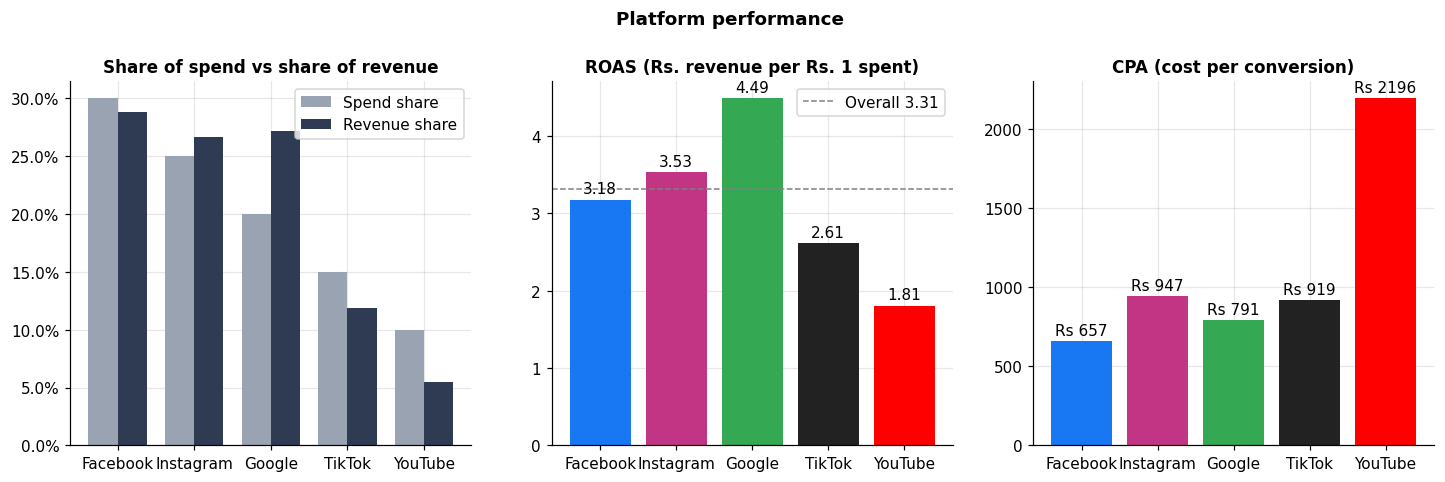

In [7]:
plat = kpis.kpi_table(df, "platform", sort_by=None).reindex(viz.PLATFORM_ORDER)
plat.to_csv(REP_DIR / "02_kpi_platform.csv")      # reference result: MapReduce & Spark must match this
display(kpis.view(plat).sort_values("ROAS", ascending=False))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
x, w = np.arange(len(plat)), 0.38
ax[0].bar(x - w/2, plat["spend_share_%"], w, label="Spend share", color=viz.NEUTRAL)
ax[0].bar(x + w/2, plat["revenue_share_%"], w, label="Revenue share", color=viz.ACCENT)
ax[0].set_xticks(x, plat.index)
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter())
ax[0].set_title("Share of spend vs share of revenue")
ax[0].legend()

bars = ax[1].bar(plat.index, plat.ROAS, color=viz.colors_for(plat.index))
ax[1].bar_label(bars, fmt="%.2f", padding=2)
ax[1].axhline(overall["ROAS"], ls="--", c="grey", lw=1, label=f"Overall {overall['ROAS']:.2f}")
ax[1].set_title("ROAS (Rs. revenue per Rs. 1 spent)")
ax[1].legend()

bars = ax[2].bar(plat.index, plat.CPA, color=viz.colors_for(plat.index))
ax[2].bar_label(bars, fmt="Rs %.0f", padding=2)
ax[2].set_title("CPA (cost per conversion)")

fig.suptitle("Platform performance", fontweight="bold", y=1.03)
viz.save(fig, FIG_DIR, "02_platform_performance"); plt.show()

## 6. Campaign performance

Top 10 campaigns by ROAS


,platform,type,Spend (Rs M),Revenue (Rs M),Spend share %,Revenue share %,CTR %,CPC (Rs),Conv. rate %,CPA (Rs),ROAS
campaign,,,,,,,,,,,
GG_Retargeting_02,Google,Retargeting,382.74,3608.91,2.00,5.70,3.73,24.12,6.41,376.24,9.43
GG_Retargeting_01,Google,Retargeting,383.58,3606.26,2.00,5.69,3.73,24.17,6.39,378.03,9.40
IG_Retargeting_01,Instagram,Retargeting,478.41,3553.39,2.50,5.61,1.24,14.47,3.21,450.79,7.43
IG_Retargeting_02,Instagram,Retargeting,478.14,3539.29,2.50,5.59,1.24,14.48,3.21,451.48,7.40
FB_Retargeting_01,Facebook,Retargeting,574.61,3838.11,3.00,6.06,1.49,10.06,3.21,313.21,6.68
FB_Retargeting_02,Facebook,Retargeting,571.97,3818.06,2.99,6.03,1.49,10.05,3.21,313.05,6.68
TT_Retargeting_02,TikTok,Retargeting,288.69,1585.62,1.51,2.50,0.99,7.04,1.61,437.73,5.49
TT_Retargeting_01,TikTok,Retargeting,286.08,1569.97,1.49,2.48,1.00,7.04,1.61,437.91,5.49
GG_Promo_02,Google,Promo,384.22,2025.50,2.01,3.20,3.30,27.24,4.05,673.42,5.27


Bottom 5 campaigns by ROAS


,platform,type,Spend (Rs M),Revenue (Rs M),Spend share %,Revenue share %,CTR %,CPC (Rs),Conv. rate %,CPA (Rs),ROAS
campaign,,,,,,,,,,,
GG_Brand_01,Google,Brand,575.27,686.07,3.00,1.08,2.01,44.82,1.51,2969.31,1.19
IG_Brand_01,Instagram,Brand,715.55,670.61,3.74,1.06,0.67,26.89,0.76,3554.77,0.94
FB_Brand_01,Facebook,Brand,862.19,733.59,4.50,1.16,0.80,18.68,0.76,2458.40,0.85
TT_Brand_01,TikTok,Brand,431.35,300.86,2.25,0.48,0.54,13.06,0.38,3443.95,0.70
YT_Brand_01,YouTube,Brand,287.88,139.94,1.50,0.22,0.27,37.28,0.46,8171.12,0.49


By campaign type


,Spend (Rs M),Revenue (Rs M),Spend share %,Revenue share %,CTR %,CPC (Rs),Conv. rate %,CPA (Rs),ROAS
type,,,,,,,,,
Retargeting,3827.09,26571.22,19.98,41.95,1.21,12.25,3.04,403.16,6.94
Promo,3831.99,14855.92,20.01,23.46,1.07,13.84,1.92,721.67,3.88
Prospecting,8622.45,19377.27,45.02,30.59,0.93,15.91,1.28,1244.19,2.25
Brand,2872.23,2531.06,15.00,4.00,0.65,22.73,0.72,3169.46,0.88


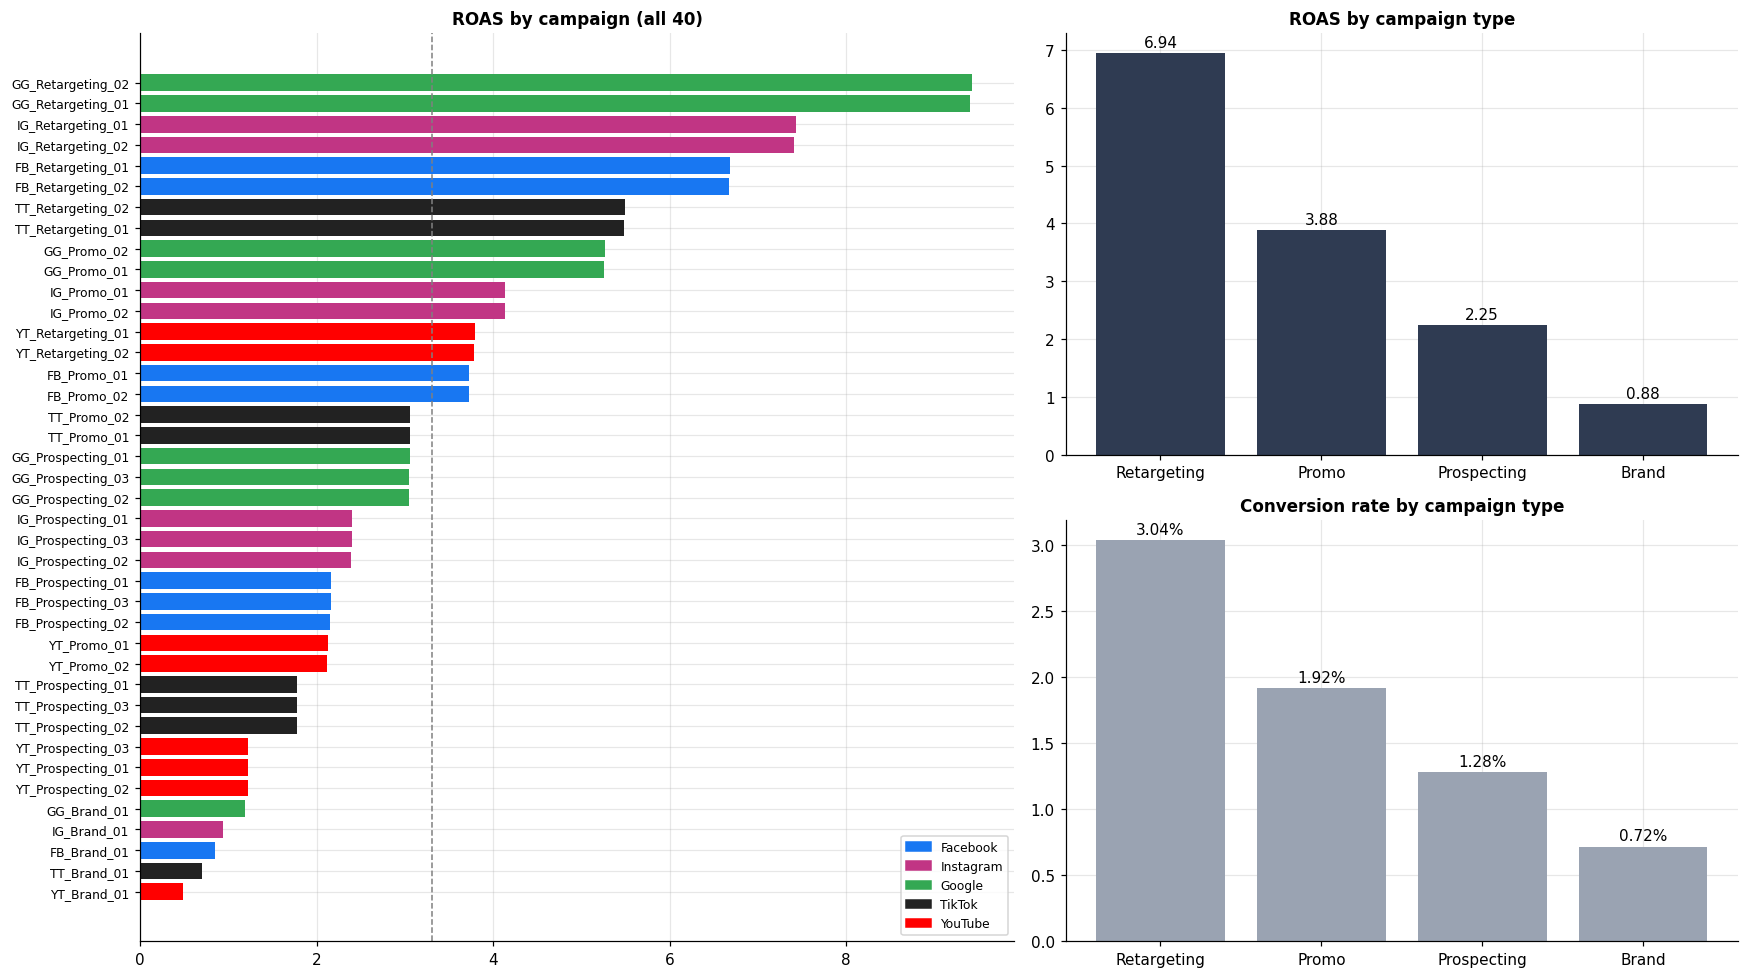

In [8]:
camp = kpis.kpi_table(df, "campaign")
code_to_platform = {v["code"]: k for k, v in CONFIG["platforms"].items()}
parts = pd.Series(camp.index.astype(str), index=camp.index).str.split("_", expand=True)
camp.insert(0, "platform", parts[0].map(code_to_platform))
camp.insert(1, "type", parts[1])
camp.to_csv(REP_DIR / "02_kpi_campaign.csv")

ctype = kpis.add_kpis(camp.groupby("type")[kpis.METRICS].sum()).sort_values("ROAS", ascending=False)
ctype.to_csv(REP_DIR / "02_kpi_campaign_type.csv")

print("Top 10 campaigns by ROAS")
display(pd.concat([camp[["platform", "type"]], kpis.view(camp)], axis=1).head(10))
print("Bottom 5 campaigns by ROAS")
display(pd.concat([camp[["platform", "type"]], kpis.view(camp)], axis=1).tail(5))
print("By campaign type")
display(kpis.view(ctype))

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, width_ratios=[1.3, 1])
a0 = fig.add_subplot(gs[:, 0])
c = camp.sort_values("ROAS")
a0.barh(c.index, c.ROAS, color=viz.colors_for(c.platform))
a0.axvline(overall["ROAS"], ls="--", c="grey", lw=1)
a0.set_title("ROAS by campaign (all 40)")
a0.tick_params(axis="y", labelsize=8)
viz.platform_legend(a0, loc="lower right", fontsize=8)

a1 = fig.add_subplot(gs[0, 1])
b = a1.bar(ctype.index, ctype.ROAS, color=viz.ACCENT)
a1.bar_label(b, fmt="%.2f", padding=2)
a1.set_title("ROAS by campaign type")

a2 = fig.add_subplot(gs[1, 1])
b = a2.bar(ctype.index, ctype["CVR_%"], color=viz.NEUTRAL)
a2.bar_label(b, fmt="%.2f%%", padding=2)
a2.set_title("Conversion rate by campaign type")
fig.tight_layout()
viz.save(fig, FIG_DIR, "02_campaign_performance"); plt.show()

## 7. Audience performance

By age


,Spend (Rs M),Revenue (Rs M),Spend share %,Revenue share %,CTR %,CPC (Rs),Conv. rate %,CPA (Rs),ROAS
age,,,,,,,,,
35-44,3650.54,13960.69,19.06,22.04,0.96,17.78,2.42,735.82,3.82
25-34,6453.05,24289.74,33.69,38.35,0.99,15.22,2.04,744.35,3.76
45-54,2002.11,6341.04,10.45,10.01,0.92,19.04,2.16,883.28,3.17
18-24,5880.80,15895.03,30.70,25.10,0.99,12.63,1.22,1031.52,2.70
55+,1167.26,2848.97,6.09,4.50,0.91,20.17,1.80,1121.66,2.44


By gender


,Spend (Rs M),Revenue (Rs M),Spend share %,Revenue share %,CTR %,CPC (Rs),Conv. rate %,CPA (Rs),ROAS
gender,,,,,,,,,
Female,7179.13,26238.80,37.48,41.43,0.98,15.27,1.96,779.00,3.65
Male,11974.64,37096.67,62.52,58.57,0.97,15.20,1.70,892.08,3.10


By city


,Spend (Rs M),Revenue (Rs M),Spend share %,Revenue share %,CTR %,CPC (Rs),Conv. rate %,CPA (Rs),ROAS
city,,,,,,,,,
Islamabad,1917.41,9009.56,10.01,14.23,0.97,15.22,2.14,712.06,4.70
Lahore,4218.01,15692.22,22.02,24.78,0.97,15.23,1.92,791.92,3.72
Karachi,4596.67,16636.03,24.00,26.27,0.97,15.23,1.87,813.77,3.62
Rawalpindi,1533.48,4798.40,8.01,7.58,0.97,15.24,1.78,856.53,3.13
Sialkot,1148.98,3252.35,6.00,5.14,0.97,15.23,1.69,899.47,2.83
Faisalabad,1530.59,3979.62,7.99,6.28,0.97,15.22,1.64,928.11,2.60
Peshawar,1340.35,3397.28,7.00,5.36,0.97,15.21,1.60,950.31,2.53
Multan,1147.42,2779.07,5.99,4.39,0.97,15.22,1.56,973.32,2.42
Hyderabad,955.57,2156.12,4.99,3.40,0.97,15.21,1.51,1009.04,2.26


By device


,Spend (Rs M),Revenue (Rs M),Spend share %,Revenue share %,CTR %,CPC (Rs),Conv. rate %,CPA (Rs),ROAS
device,,,,,,,,,
Desktop,1956.24,8801.96,10.21,13.90,0.99,24.24,3.59,676.05,4.50
Mobile,16633.60,52791.80,86.84,83.35,0.98,14.50,1.67,869.07,3.17
Tablet,563.93,1741.71,2.94,2.75,0.80,18.88,2.03,930.86,3.09


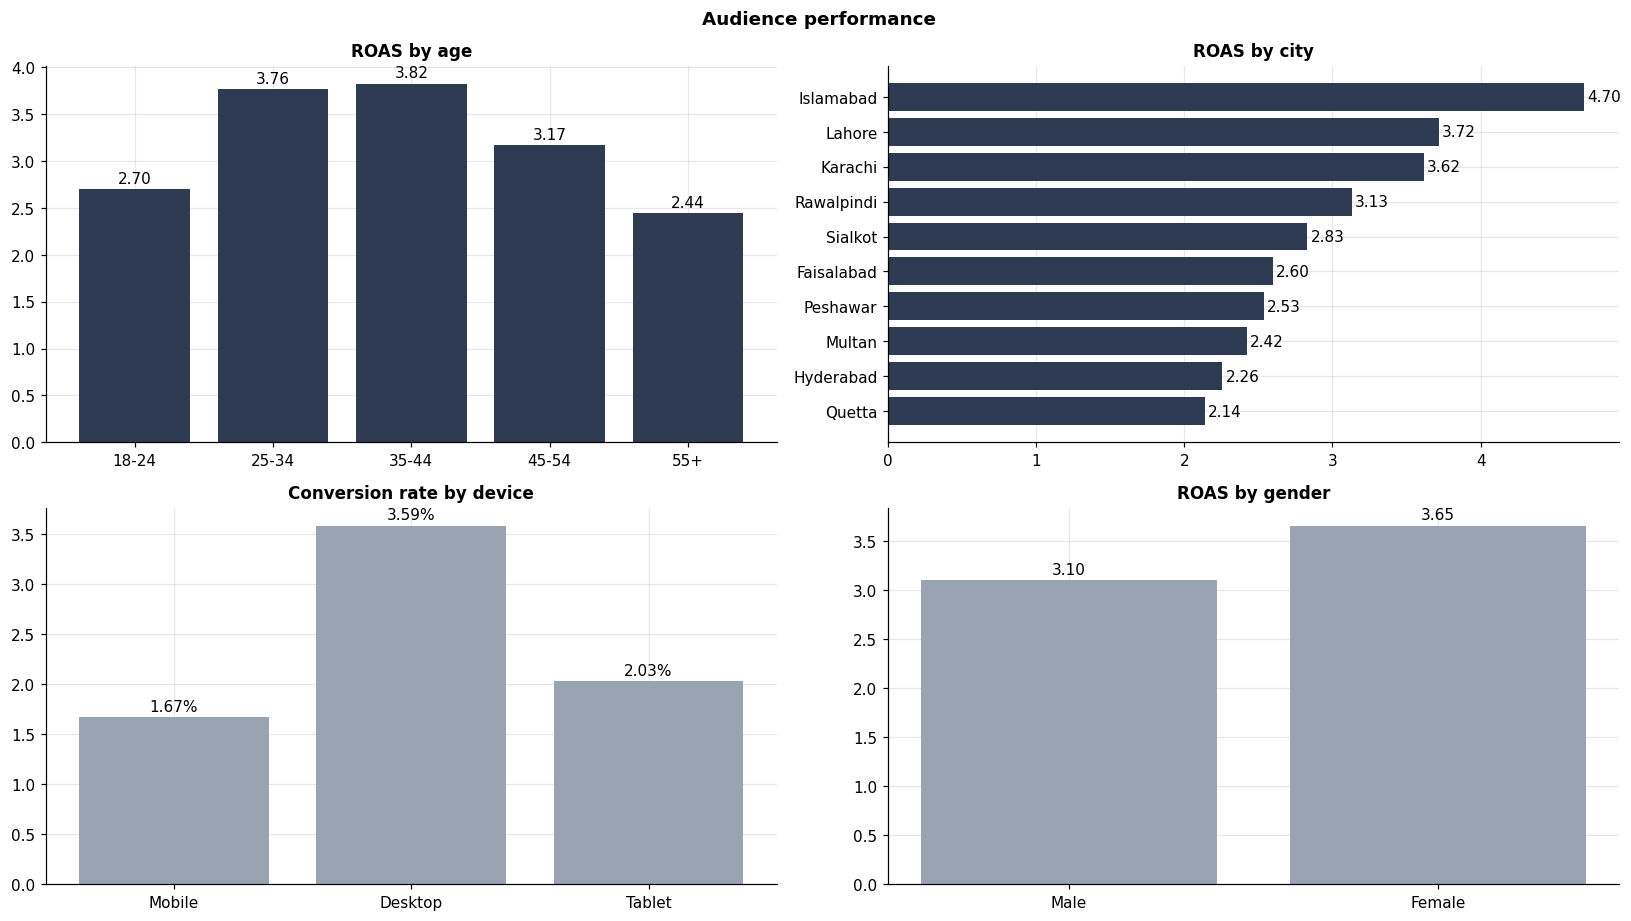

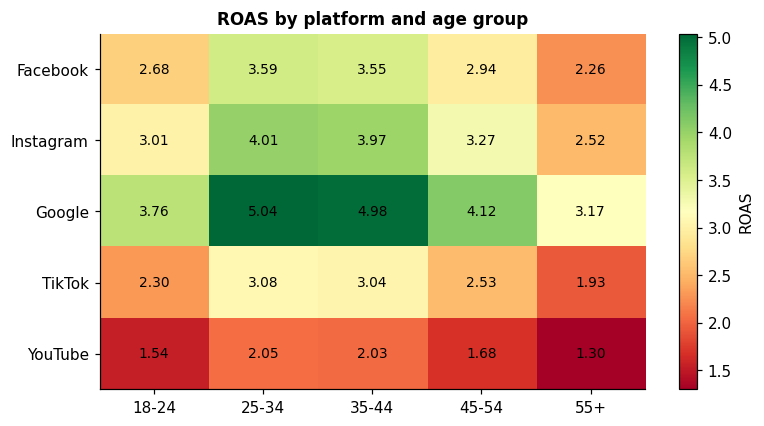

In [9]:
aud = {dim: kpis.kpi_table(df, dim, sort_by=None) for dim in ["age", "gender", "city", "device"]}
for dim, t in aud.items():
    t.to_csv(REP_DIR / f"02_kpi_{dim}.csv")
    print(f"By {dim}")
    display(kpis.view(t).sort_values("ROAS", ascending=False))

fig, ax = plt.subplots(2, 2, figsize=(15, 8.5))
b = ax[0, 0].bar(aud["age"].index.astype(str), aud["age"].ROAS, color=viz.ACCENT)
ax[0, 0].bar_label(b, fmt="%.2f", padding=2); ax[0, 0].set_title("ROAS by age")

city = aud["city"].sort_values("ROAS")
b = ax[0, 1].barh(city.index.astype(str), city.ROAS, color=viz.ACCENT)
ax[0, 1].bar_label(b, fmt="%.2f", padding=2); ax[0, 1].set_title("ROAS by city")

b = ax[1, 0].bar(aud["device"].index.astype(str), aud["device"]["CVR_%"], color=viz.NEUTRAL)
ax[1, 0].bar_label(b, fmt="%.2f%%", padding=2); ax[1, 0].set_title("Conversion rate by device")

b = ax[1, 1].bar(aud["gender"].index.astype(str), aud["gender"].ROAS, color=viz.NEUTRAL)
ax[1, 1].bar_label(b, fmt="%.2f", padding=2); ax[1, 1].set_title("ROAS by gender")
fig.suptitle("Audience performance", fontweight="bold")
fig.tight_layout()
viz.save(fig, FIG_DIR, "02_audience_performance"); plt.show()

# Platform x age heatmap: who should each platform target?
pa_roas = kpis.kpi_table(df, ["platform", "age"], sort_by=None)["ROAS"].unstack().reindex(viz.PLATFORM_ORDER)
pa_roas.to_csv(REP_DIR / "02_roas_platform_x_age.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(pa_roas.values, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(pa_roas.shape[1]), pa_roas.columns.astype(str))
ax.set_yticks(range(pa_roas.shape[0]), pa_roas.index)
ax.grid(False)
for i in range(pa_roas.shape[0]):
    for j in range(pa_roas.shape[1]):
        ax.text(j, i, f"{pa_roas.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="ROAS")
ax.set_title("ROAS by platform and age group")
viz.save(fig, FIG_DIR, "02_heatmap_platform_age"); plt.show()

## 8. Trends over time
Daily totals per platform are also saved to `data/processed/`. Notebook 06 uses this compact table
(1,825 rows instead of 10M) to fit its response curves.

Daily platform table: 1,825 rows (from 10,000,000)


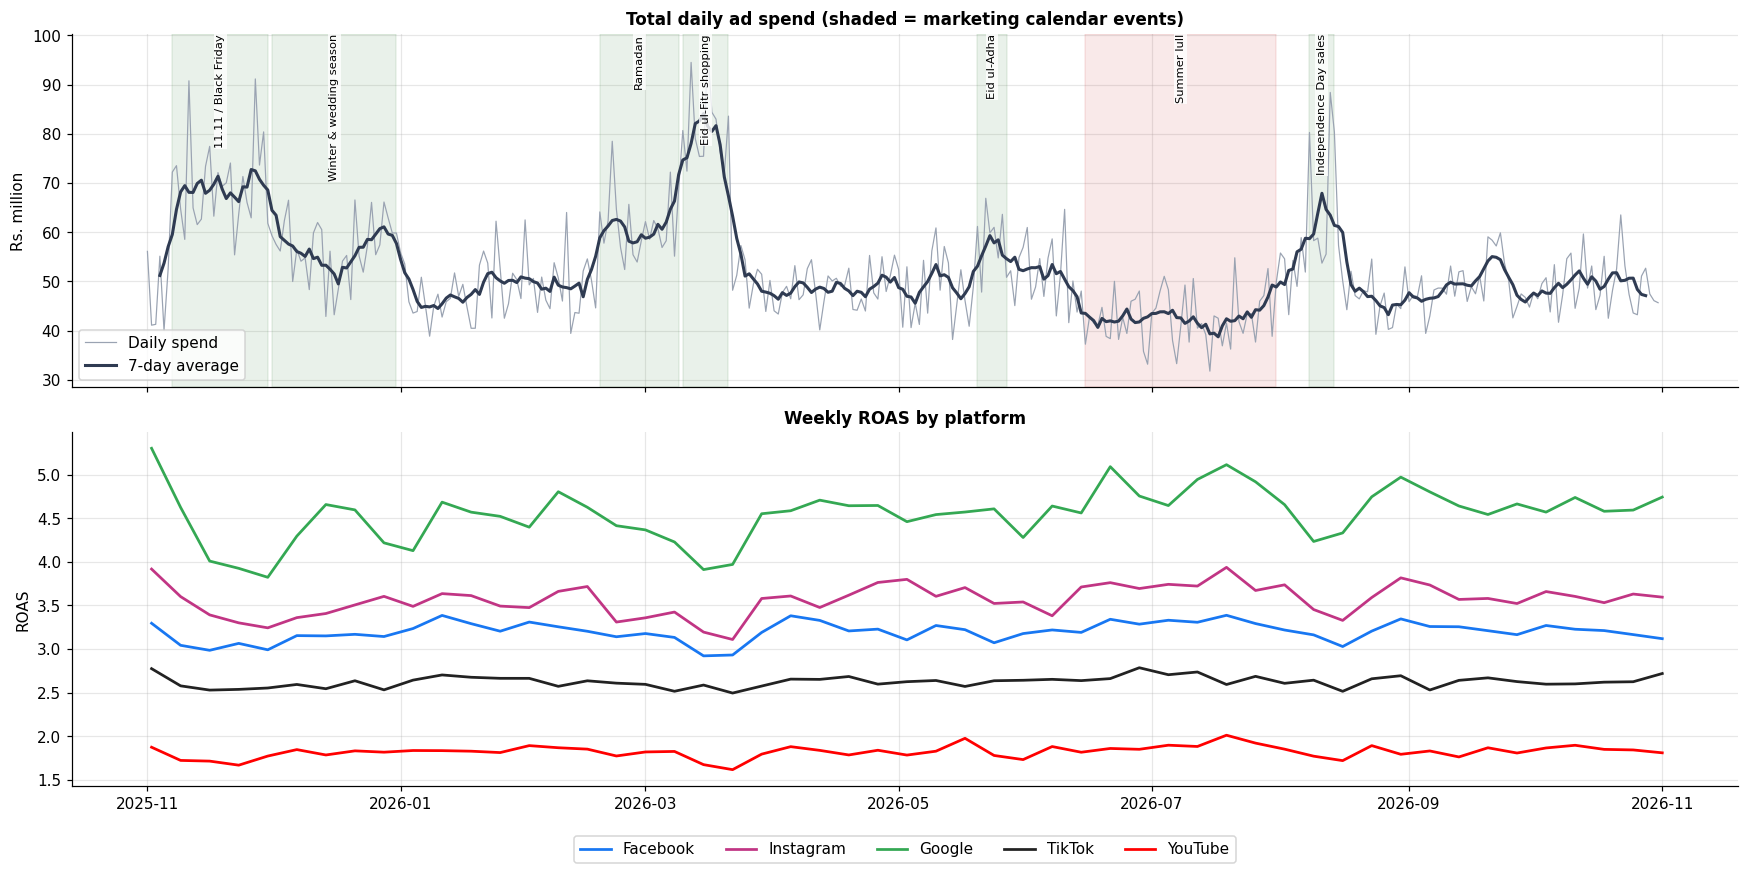

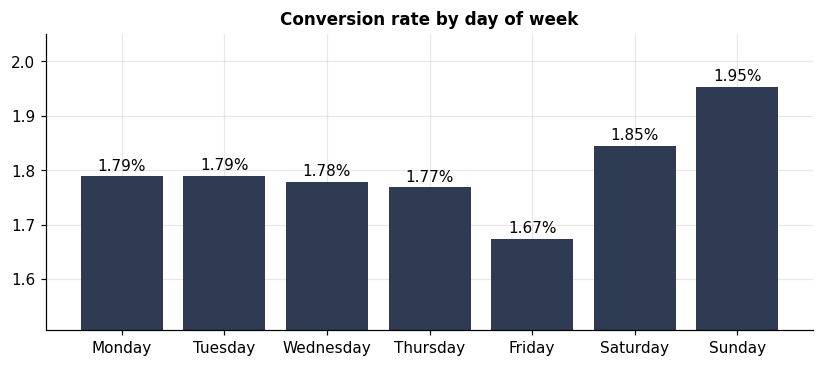

In [10]:
daily = df.groupby(["date", "platform"], observed=True)[kpis.METRICS].sum().reset_index()
daily.to_parquet(PROC_DIR / f"daily_platform_{DATASET}.parquet", index=False)
print(f"Daily platform table: {len(daily):,} rows (from {len(df):,})")

spend = daily.pivot(index="date", columns="platform", values="spend")[viz.PLATFORM_ORDER]
rev = daily.pivot(index="date", columns="platform", values="revenue")[viz.PLATFORM_ORDER]
total = spend.sum(axis=1) / 1e6
weekly_roas = rev.resample("W").sum() / spend.resample("W").sum()

fig, ax = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
ax[0].plot(total.index, total, color=viz.NEUTRAL, lw=0.8, label="Daily spend")
ax[0].plot(total.index, total.rolling(7, center=True).mean(), color=viz.ACCENT, lw=2, label="7-day average")
for s in CONFIG["seasons"]:
    s0, s1 = pd.Timestamp(s["start"]), pd.Timestamp(s["end"])
    shade = "#2E7D32" if s["budget_multiplier"] > 1 else "#C62828"
    ax[0].axvspan(s0, s1, color=shade, alpha=0.10)
    ax[0].text(s0 + (s1 - s0) / 2, ax[0].get_ylim()[1], s["event"], ha="center", va="top", fontsize=7.5, rotation=90,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax[0].set_ylabel("Rs. million"); ax[0].set_title("Total daily ad spend (shaded = marketing calendar events)")
ax[0].legend(loc="lower left")

for p in viz.PLATFORM_ORDER:
    ax[1].plot(weekly_roas.index, weekly_roas[p], color=viz.PLATFORM_COLORS[p], lw=1.8, label=p)
ax[1].set_ylabel("ROAS"); ax[1].set_title("Weekly ROAS by platform")
ax[1].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
viz.save(fig, FIG_DIR, "02_time_trends"); plt.show()

# Day-of-week effect
dow = daily.groupby(daily.date.dt.day_name())[kpis.METRICS].sum()
dow = kpis.add_kpis(dow).reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
dow.to_csv(REP_DIR / "02_kpi_weekday.csv")
fig, ax = plt.subplots(figsize=(9, 3.5))
b = ax.bar(dow.index, dow["CVR_%"], color=viz.ACCENT)
ax.bar_label(b, fmt="%.2f%%", padding=2)
ax.set_ylim(dow["CVR_%"].min() * 0.9, dow["CVR_%"].max() * 1.05)
ax.set_title("Conversion rate by day of week")
viz.save(fig, FIG_DIR, "02_weekday_conversion"); plt.show()

## 9. Diminishing returns
On days a platform spends more than usual, does each rupee earn less?
If so, simply moving all budget to the highest-ROAS platform would be a mistake:
its ROAS would fall as spend rises. Notebook 06 models this properly.

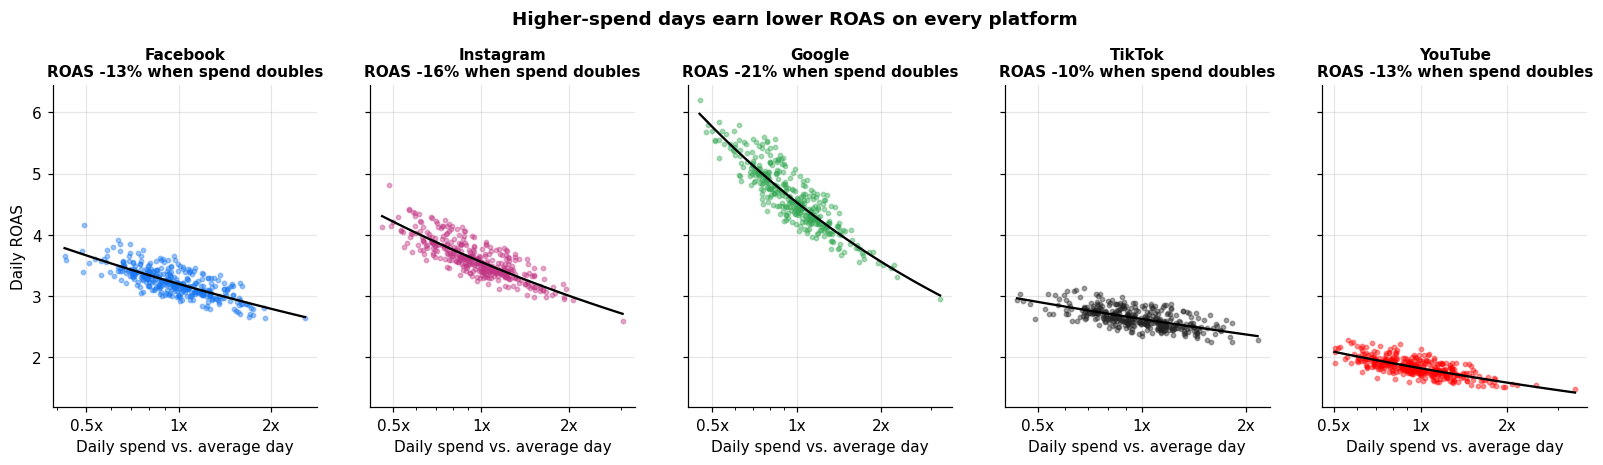

In [11]:
fig, ax = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True)
doubling = {}
for a, p in zip(ax, viz.PLATFORM_ORDER):
    d = daily[daily.platform == p]
    s_idx = d.spend / d.spend.mean()
    roas_d = d.revenue / d.spend
    slope, icpt = np.polyfit(np.log(s_idx), np.log(roas_d), 1)
    doubling[p] = 2 ** slope - 1
    a.scatter(s_idx, roas_d, s=8, alpha=0.4, color=viz.PLATFORM_COLORS[p])
    xs = np.linspace(s_idx.min(), s_idx.max(), 50)
    a.plot(xs, np.exp(icpt) * xs ** slope, color="black", lw=1.5)
    a.set_xscale("log")
    a.set_xticks([0.5, 1, 2], ["0.5x", "1x", "2x"])
    a.xaxis.set_minor_formatter(mtick.NullFormatter())
    a.set_title(f"{p}\nROAS {doubling[p]:+.0%} when spend doubles", fontsize=10)
    a.set_xlabel("Daily spend vs. average day")
ax[0].set_ylabel("Daily ROAS")
fig.suptitle("Higher-spend days earn lower ROAS on every platform", fontweight="bold", y=1.06)
viz.save(fig, FIG_DIR, "02_diminishing_returns"); plt.show()
pd.Series(doubling, name="roas_change_when_spend_doubles").to_csv(REP_DIR / "02_diminishing_returns.csv")

## 10. Key insights

In [12]:
best, worst = plat.ROAS.idxmax(), plat.ROAS.idxmin()
gap = (plat["revenue_share_%"] - plat["spend_share_%"]).sort_values(ascending=False)
under = [f"{p} (+{g:.1f} pts)" for p, g in gap.items() if g > 0]
over = [f"{p} ({g:.1f} pts)" for p, g in gap.items() if g < 0]
age, city, dev = aud["age"].ROAS.idxmax(), aud["city"].ROAS.idxmax(), aud["device"]["CVR_%"].idxmax()
steep = min(doubling, key=doubling.get)
flat = max(doubling, key=doubling.get)

insights = f"""
1. **{best}** has the highest ROAS (**{plat.ROAS[best]:.2f}**) but receives only **{plat.loc[best, 'spend_share_%']:.0f}%** of spend.
   **{worst}** has the lowest ROAS (**{plat.ROAS[worst]:.2f}**), with a CPA of Rs. {plat.CPA[worst]:,.0f}.
2. Platforms earning a bigger share of revenue than of spend: {", ".join(under)}.
   Platforms earning less than their spend share: {", ".join(over)}.
3. **{ctype.ROAS.idxmax()}** campaigns return the most (ROAS {ctype.ROAS.max():.2f});
   **{ctype.ROAS.idxmin()}** campaigns the least (ROAS {ctype.ROAS.min():.2f}). Brand campaigns build awareness, so judge them on reach, not ROAS alone.
4. Best audience: age **{age}**, city **{city}**; **{dev}** users convert best ({aud['device'].loc[dev, 'CVR_%']:.2f}%).
5. Every platform shows diminishing returns. When daily spend doubles, ROAS falls most on **{steep}** ({doubling[steep]:+.0%})
   and least on **{flat}** ({doubling[flat]:+.0%}). The best platform today is not automatically the best home for *extra* budget.
"""
(REP_DIR / "02_key_insights.md").write_text(insights)
display(Markdown(insights))


1. **Google** has the highest ROAS (**4.49**) but receives only **20%** of spend.
   **YouTube** has the lowest ROAS (**1.81**), with a CPA of Rs. 2,196.
2. Platforms earning a bigger share of revenue than of spend: Google (+7.1 pts), Instagram (+1.7 pts).
   Platforms earning less than their spend share: Facebook (-1.2 pts), TikTok (-3.1 pts), YouTube (-4.5 pts).
3. **Retargeting** campaigns return the most (ROAS 6.94);
   **Brand** campaigns the least (ROAS 0.88). Brand campaigns build awareness, so judge them on reach, not ROAS alone.
4. Best audience: age **35-44**, city **Islamabad**; **Desktop** users convert best (3.59%).
5. Every platform shows diminishing returns. When daily spend doubles, ROAS falls most on **Google** (-21%)
   and least on **TikTok** (-10%). The best platform today is not automatically the best home for *extra* budget.


In [13]:
print("Saved reports:")
for p in sorted(REP_DIR.glob("02_*")):
    print("  outputs/reports/" + p.name)
print("Saved figures:")
for p in sorted(FIG_DIR.glob("02_*")):
    print("  outputs/figures/" + p.name)
print(f"Processed data:\n  data/processed/daily_platform_{DATASET}.parquet")

Saved reports:
  outputs/reports/02_data_quality.csv
  outputs/reports/02_diminishing_returns.csv
  outputs/reports/02_key_insights.md
  outputs/reports/02_kpi_age.csv
  outputs/reports/02_kpi_campaign.csv
  outputs/reports/02_kpi_campaign_type.csv
  outputs/reports/02_kpi_city.csv
  outputs/reports/02_kpi_device.csv
  outputs/reports/02_kpi_gender.csv
  outputs/reports/02_kpi_overall.csv
  outputs/reports/02_kpi_platform.csv
  outputs/reports/02_kpi_weekday.csv
  outputs/reports/02_roas_platform_x_age.csv
Saved figures:
  outputs/figures/02_audience_performance.png
  outputs/figures/02_campaign_performance.png
  outputs/figures/02_diminishing_returns.png
  outputs/figures/02_heatmap_platform_age.png
  outputs/figures/02_platform_performance.png
  outputs/figures/02_time_trends.png
  outputs/figures/02_weekday_conversion.png
Processed data:
  data/processed/daily_platform_10m.parquet


## ✅ Notebook 02 complete

**Answered so far:** how every platform, campaign and audience performs, and evidence that returns diminish as spend rises.

